# Бизнес-сообщества для VK Маркета

**Идея:** площадка с акцентом на товары самостоятельных бизнес-сообществ со своей аудиторией. Продажа товаров на Ozon или другой площадке не является основанием исключать сообщество.

Здесь небольшой отдельный анализ: **аудитория → товары и контент → внимание и заказы**. Это три направления оценки одного бизнеса, а не три взаимоисключающие группы.

## Подготовка

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_FILE = Path("data/businesses_clean.csv")
MIN_AUDIENCE = 1000
MIN_PUBLICATIONS = 1
df = pd.read_csv(DATA_FILE)

### Настройка темы графиков

In [2]:
PRIMARY_COLOR = "#0077FF"
SECONDARY_COLOR = "#8024C0"
CHART_PALETTE = [PRIMARY_COLOR, SECONDARY_COLOR, "#17D685", "#FF3985", "#00EAFF"]
SEQUENTIAL_CMAP = sns.blend_palette(["#FFFFFF", PRIMARY_COLOR], as_cmap=True)
DIVERGING_CMAP = sns.blend_palette([SECONDARY_COLOR, "#FFFFFF", PRIMARY_COLOR], as_cmap=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans", palette=CHART_PALETTE, rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "#212121", "axes.labelcolor": "#212121",
    "xtick.color": "#212121", "ytick.color": "#212121",
    "grid.color": "#DEDEDE", "grid.alpha": .6, "grid.linewidth": .6,
    "axes.edgecolor": "#DEDEDE", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlepad": 16, "axes.labelpad": 10,
    "legend.frameon": False, "figure.dpi": 120, "savefig.dpi": 160,
})

## (1) Товарные сообщества

**Вопрос:** сколько бизнесов уже имеют активные товары и используют контент?

Берём **все сообщества с активными товарами**, независимо от чекаута и заявленного типа бизнеса. В таблице доли считаются от этой товарной выборки. Строки пересекаются и не образуют воронку.

In [3]:
publication_columns = ["Посты за 30 дней", "Клипы за 30 дней", "Посты с товаром за 30 дней", "Клипы с товаром за 30 дней"]
goods = df.loc[df["Число активных товаров в каталоге"].gt(0)].copy()
goods["Публикаций"] = goods[publication_columns].sum(axis=1)
goods["Есть товарные просмотры"] = goods["Просмотры товарного контента"].gt(0)
goods["Есть заказы"] = goods["Заказы через чекаут"].gt(0)
goods["Аудитория"] = pd.cut(goods["Число подписчиков"], [0, 1000, 10000, float("inf")], right=False,
                            labels=["До 1 000", "1 000–9 999", "От 10 000"])
supply_counts = pd.Series({"Есть активные товары": len(goods),
    "Есть товары и публикации за месяц": goods["Публикаций"].gt(0).sum(),
    "Есть товары и товарные просмотры": goods["Есть товарные просмотры"].sum(),
    "Есть товары и заказы за период": goods["Есть заказы"].sum()}, name="Бизнесов")
supply_summary = supply_counts.to_frame()
supply_summary["Доля товарных бизнесов, %"] = supply_summary["Бизнесов"] / len(goods) * 100
display(supply_summary.round(2).rename_axis("Признак").reset_index())

,Признак,Бизнесов,"Доля товарных бизнесов, %"
0,Есть активные товары,3961,100.00
1,Есть товары и публикации за месяц,3004,75.84
2,Есть товары и товарные просмотры,1117,28.20
3,Есть товары и заказы за период,285,7.20


**Вывод:** активные товары есть у **3 961 бизнеса**. Из них **3 004** публиковали контент за месяц, у **1 117 (28,20%)** есть товарные просмотры, у **285 (7,20%)** — заказы через чекаут.

Это доли бизнесов, а не покупателей. Их разница не показывает, сколько людей потерялось между просмотром и заказом: строки таблицы не являются этапами пути одних и тех же покупателей.

**Важно:** учитываем только заказы, оформленные через чекаут. Покупатель мог увидеть товар во ВКонтакте, связаться с продавцом и оформить покупку в сообщениях, на сайте или другим способом. Такая продажа не входит в показатель «Заказы через чекаут»; отсутствие этих заказов не означает отсутствия продаж вообще.

## (2) Аудитория и внимание к товарам

**Вопрос:** как различаются товарные сообщества с малой, средней и большой аудиторией?

Разделяем сообщества по числу подписчиков: **до 1 000, 1 000–9 999 и от 10 000**. В двух последних столбцах — **бизнесов с результатом из общего числа (их доля)**. Заказы учитываются за период независимо от текущего статуса чекаута.

,Аудитория,Бизнесов,"Товаров, медиана",С товарными просмотрами,С заказами
0,До 1 000,2219,9.0,"602 из 2219 (27,13%)","68 из 2219 (3,06%)"
1,1 000–9 999,1487,15.0,"411 из 1487 (27,64%)","145 из 1487 (9,75%)"
2,От 10 000,255,38.0,"104 из 255 (40,78%)","72 из 255 (28,24%)"


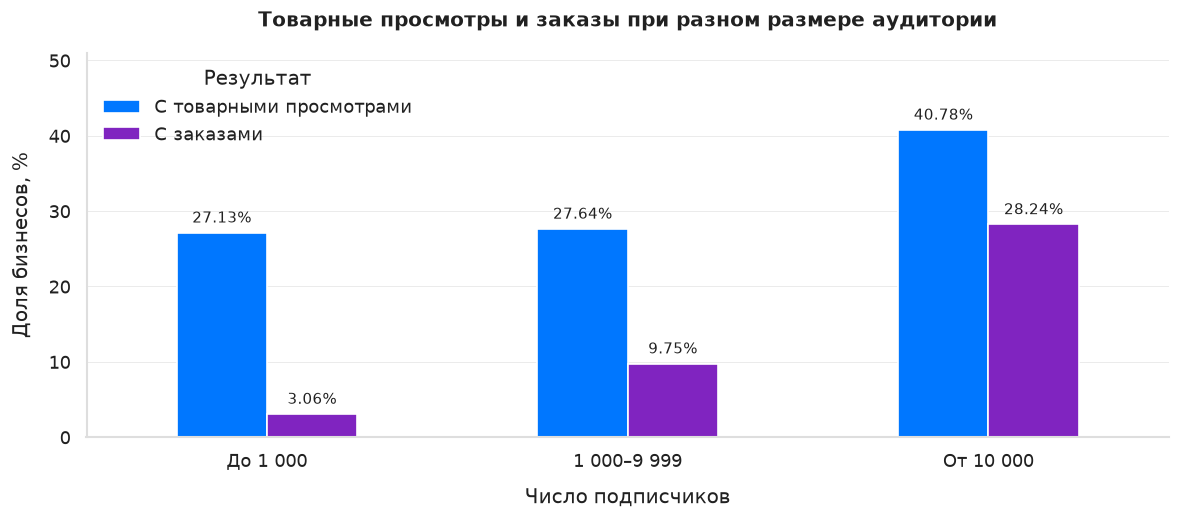

In [4]:
audience_profile = goods.groupby("Аудитория", observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "Товаров, медиана": ("Число активных товаров в каталоге", "median"),
    "С товарными просмотрами": ("Есть товарные просмотры", "sum"), "С заказами": ("Есть заказы", "sum")})
audience_readable = audience_profile[["Бизнесов", "Товаров, медиана"]].copy()
for column in ["С товарными просмотрами", "С заказами"]:
    audience_readable[column] = [
        f"{int(count)} из {int(total)} ({count / total * 100:.2f}%)".replace(".", ",")
        for count, total in audience_profile[[column, "Бизнесов"]].itertuples(index=False, name=None)]
display(audience_readable.reset_index())
audience_rates = audience_profile[["С товарными просмотрами", "С заказами"]].div(audience_profile["Бизнесов"], axis=0) * 100
ax = audience_rates.plot.bar(figsize=(10, 4.5), rot=0, color=[PRIMARY_COLOR, SECONDARY_COLOR])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=9)
ax.set(title="Товарные просмотры и заказы при разном размере аудитории",
       xlabel="Число подписчиков", ylabel="Доля бизнесов, %", ylim=(0, audience_rates.max().max() * 1.25))
ax.legend(title="Результат")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Что это означает:** размер аудитории учитываем отдельно от наличия товаров. Группы также различаются каталогом, поэтому более высокую долю заказов не объясняем только подписчиками.

## (3) Сообщество, которое ведётся и имеет аудиторию

**Вопрос:** какие сочетания интереса и заказов есть у товарных сообществ с аудиторией и свежим контентом?

Для компактного примера берём активные товары, **от 1 000 подписчиков и хотя бы одну публикацию за месяц**. Это настройки среза `MIN_AUDIENCE` и `MIN_PUBLICATIONS`, а не доказанные критерии лучшего продавца. Их можно менять в подготовке.

Группы ниже не пересекаются: сначала выделяем бизнесы с заказами, затем остальные по открытиям и просмотрам. Это состояния бизнесов, не пользовательская воронка.

,Состояние,Бизнесов,"Доля выбранного среза, %","С чекаутом, %"
0,Есть заказы,192,13.87,96.35
1,"Есть открытия, нет заказов",129,9.32,77.52
2,"Есть просмотры, нет открытий и заказов",226,16.33,84.51
3,"Нет товарных просмотров, открытий и заказов",837,60.48,90.08


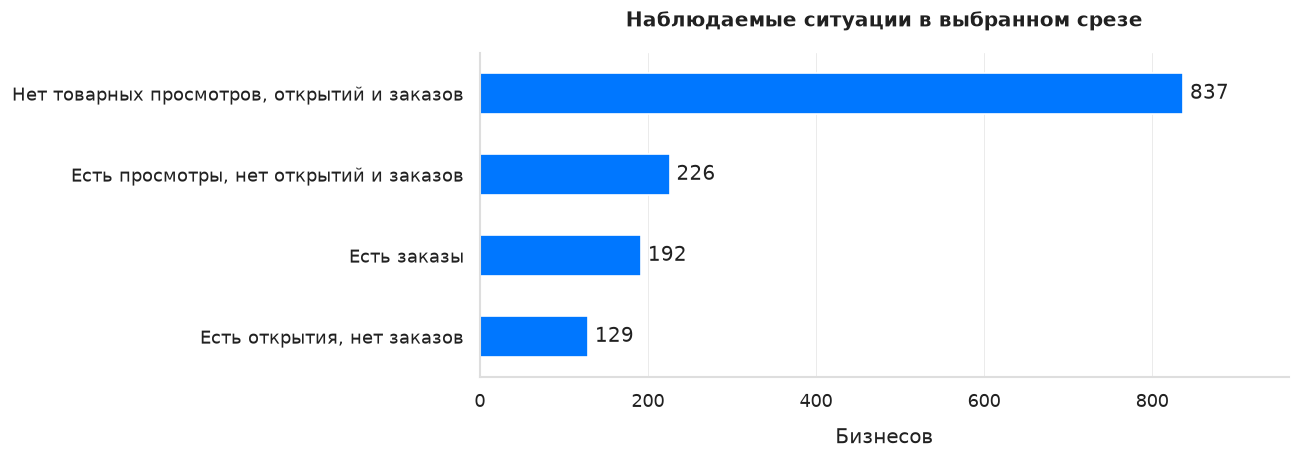

In [5]:
community_core = goods.loc[goods["Число подписчиков"].ge(MIN_AUDIENCE)
    & goods["Публикаций"].ge(MIN_PUBLICATIONS)].copy()
community_core["Состояние"] = "Нет товарных просмотров, открытий и заказов"
community_core.loc[community_core["Есть товарные просмотры"], "Состояние"] = "Есть просмотры, нет открытий и заказов"
community_core.loc[community_core["Открытия карточки товара из контента"].gt(0), "Состояние"] = "Есть открытия, нет заказов"
community_core.loc[community_core["Есть заказы"], "Состояние"] = "Есть заказы"
core_states = community_core.groupby("Состояние").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С чекаутом": ("Подключён чекаут", "sum")})
core_states["Доля выбранного среза, %"] = core_states["Бизнесов"] / len(community_core) * 100
core_states["С чекаутом, %"] = core_states["С чекаутом"] / core_states["Бизнесов"] * 100
display(core_states[["Бизнесов", "Доля выбранного среза, %", "С чекаутом, %"]].round(2).reset_index())
ax = core_states["Бизнесов"].sort_values().plot.barh(figsize=(11, 4), color=PRIMARY_COLOR)
ax.bar_label(ax.containers[0], padding=4, fmt="%.0f")
ax.set(title="Наблюдаемые ситуации в выбранном срезе", xlabel="Бизнесов", ylabel="")
ax.margins(x=.15)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Вывод:** в выбранном срезе **1 384 бизнеса**; чекаут подключён у **1 230**, товарные просмотры есть у **460**, заказы — у **192**. Даже при наличии аудитории, активных товаров и публикаций бизнесы находятся в разных ситуациях по вниманию к товарам и продажам.

## (4) Тематики выбранных сообществ

Показываем шесть наиболее представленных тематик выбранного среза. Смотрим одновременно на численность, наличие товарных просмотров и заказов. Эти общие показатели не являются рейтингом будущего прироста продаж.

In [6]:
core_topics = community_core.groupby("Тематика").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С просмотрами": ("Есть товарные просмотры", "sum"),
    "С заказами": ("Есть заказы", "sum"), "Товаров, медиана": ("Число активных товаров в каталоге", "median")})
core_topics_readable = core_topics.sort_values("Бизнесов", ascending=False).head(6).copy()
for column in ["С просмотрами", "С заказами"]:
    core_topics_readable[column] = [
        f"{int(count)} из {int(total)} ({count / total * 100:.2f}%)".replace(".", ",")
        for count, total in core_topics_readable[[column, "Бизнесов"]].itertuples(index=False, name=None)]
display(core_topics_readable[["Бизнесов", "С просмотрами", "С заказами", "Товаров, медиана"]].reset_index())

,Тематика,Бизнесов,С просмотрами,С заказами,"Товаров, медиана"
0,Кулинария и еда,154,"54 из 154 (35,06%)","46 из 154 (29,87%)",48.5
1,Красота и здоровье,129,"38 из 129 (29,46%)","9 из 129 (6,98%)",11.0
2,Дом и ремонт,128,"33 из 128 (25,78%)","8 из 128 (6,25%)",29.5
3,Мода и стиль,101,"40 из 101 (39,60%)","14 из 101 (13,86%)",55.0
4,Путешествия и отдых,94,"30 из 94 (31,91%)","4 из 94 (4,26%)",8.0
5,Образование,90,"38 из 90 (42,22%)","16 из 90 (17,78%)",10.0


**Выводы:**

- **«Кулинария и еда» выделяется среди показанных тематик:** здесь больше всего бизнесов — 154, и самая высокая доля с заказами — **29,87%**.
- **Много сообществ в тематике не означает много продающих бизнесов.** В «Красоте и здоровье» 129 бизнесов, но с заказами **6,98%**; в «Доме и ремонте» — 128 и **6,25%**.
- **Самая высокая доля бизнесов с товарными просмотрами не совпадает с самой высокой долей с заказами.** В «Образовании» просмотры есть у **42,22%**, заказы — у **17,78%**; в «Кулинарии и еде» — у **35,06%** и **29,87%** соответственно.

**Что это означает:** даже среди сообществ с активными товарами, аудиторией от 1 000 подписчиков и публикациями результаты различаются по тематикам. Одних этих условий недостаточно, чтобы ожидать одинаковых продаж.